# Rajuk Image Level Classifier — Bare Neural Network (MLP)

**Architecture:** Fully-connected Multi-Layer Perceptron (MLP) only.  
No convolutions, no pretrained weights, no feature extractors.

**Input:** Raw flattened pixel values → 128×128×3 = **49,152 features per image**

**Pipeline:**
1. Mount Drive & Import Libraries  
2. Configuration  
3. Load Labels  
4. Collect Paths & Leakage-Free Split  
5. Sample Image Preview  
6. Dataset (flatten pixels → MLP input)  
7. DataLoaders  
8. MLP Architecture  
9. Weighted Loss & Helpers  
10. K-Fold Cross-Validation  
11. Fine-tune & Evaluate  
12. Classification Report & Confusion Matrix  
13. Learning Curves (Train / Val / Test error by dataset size)  
14. Full Training History  
15. Save Model  
16. Sanity Check

## 1. Mount Drive

In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Import Libraries

In [8]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold

# ── Reproducibility ───────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 3. Configuration

In [9]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DRIVE_BASE    = Path('/content/drive/MyDrive/ML_Lab')
AUGMENTED_DIR = DRIVE_BASE / 'Augmented_raw_data'
REAL_DIR      = DRIVE_BASE / 'raw_data' / 'final train image'
XLSX_PATH     = DRIVE_BASE / 'Rajuk_ML_DataSet.xlsx'
CSV_PATH      = DRIVE_BASE / 'Real ML_DataSet.csv'

# ── Image & MLP settings ───────────────────────────────────────────────────────
CLASS_NAMES   = ['negative', 'moderate', 'positive']
ALLOWED_EXTS  = {'.jpg', '.jpeg', '.png', '.bmp'}

# 128x128 → 49,152 input features per image
# RAM: 2700 images * 49152 * 4 bytes (float32) = ~530 MB — safe for 12.7 GB
IMAGE_SIZE    = (128, 128)
INPUT_DIM     = IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3   # 49,152

# ── Hyper-parameters ───────────────────────────────────────────────────────────
BATCH_SIZE    = 32
LR            = 1e-3
NUM_EPOCHS    = 60
KFOLD_SPLITS  = 5
PATIENCE      = 10
WEIGHT_DECAY  = 1e-3
DROPOUT       = 0.4

# ── Learning-curve steps ───────────────────────────────────────────────────────
DATASET_STEPS = [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]

print('Configuration loaded.')
print(f'  Image size : {IMAGE_SIZE}')
print(f'  Input dim  : {INPUT_DIM:,} features per image')
print(f'  Batch size : {BATCH_SIZE}')
print(f'  Epochs     : {NUM_EPOCHS}')

Configuration loaded.
  Image size : (128, 128)
  Input dim  : 49,152 features per image
  Batch size : 32
  Epochs     : 60


## 4. Load Labels

In [10]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(df, target):
    for col in df.columns:
        if normalize_header(col) == target:
            return col
    return None

def normalize_level(value):
    if pd.isna(value):
        return None
    text = str(value).strip().lower()
    mapping = {'p': 'positive', 'positive': 'positive',
               'm': 'moderate',  'moderate': 'moderate',
               'n': 'negative',  'negative': 'negative'}
    return mapping.get(text)

def load_label_mapping(df, level_col, class_names):
    label_lookup = {name: idx for idx, name in enumerate(class_names)}
    label_map = {}
    for row_index, value in enumerate(df[level_col].tolist(), start=1):
        normalized = normalize_level(value)
        if normalized is None:
            continue
        label_map[row_index] = label_lookup[normalized]
    return label_map

if XLSX_PATH.exists():
    df = pd.read_excel(XLSX_PATH)
    source_path = XLSX_PATH
elif CSV_PATH.exists():
    df = pd.read_csv(CSV_PATH)
    source_path = CSV_PATH
else:
    raise FileNotFoundError(f'No dataset file found at {DRIVE_BASE}.')

level_col = (
    find_column(df, 'levelpositivemoderatenegative')
    or find_column(df, 'level')
)
if level_col is None:
    raise ValueError('Level column not found.')

label_map = load_label_mapping(df, level_col, CLASS_NAMES)
print(f'Loaded {len(df):,} rows | {len(label_map):,} valid labels | source: {source_path.name}')

Loaded 372 rows | 372 valid labels | source: Real ML_DataSet.csv


## 5. Collect Paths & Leakage-Free Split

Split is by **unique subject ID** first so no subject's augmented copy
leaks into val/test. Augmented images go to training only.

In [11]:
def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.lower())
    return int(match.group(1)) if match else None

def collect_all_raw(base_dir, label_map):
    paths, labels = [], []
    skip_idx = skip_lbl = 0
    if not base_dir.exists():
        return paths, labels, skip_idx, skip_lbl
    for p in base_dir.rglob('*'):
        if not (p.is_file() and p.suffix.lower() in ALLOWED_EXTS):
            continue
        idx = parse_image_index(p.stem.strip())
        if idx is None:
            skip_idx += 1; continue
        lbl = label_map.get(idx)
        if lbl is None:
            skip_lbl += 1; continue
        paths.append(p)
        labels.append(lbl)
    return paths, labels, skip_idx, skip_lbl

aug_paths,  aug_labels,  si_a, sl_a = collect_all_raw(AUGMENTED_DIR, label_map)
real_paths, real_labels, si_r, sl_r = collect_all_raw(REAL_DIR,      label_map)

print(f'Augmented images         : {len(aug_paths):,}')
print(f'Real images              : {len(real_paths):,}')
print(f'Skipped (no index)       : {si_a + si_r}')
print(f'Skipped (no label match) : {sl_a + sl_r}')

# ── Leakage-free split by unique subject ID ────────────────────────────────────
unique_indices     = sorted(set(
    parse_image_index(p.stem.strip()) for p in real_paths
    if parse_image_index(p.stem.strip()) is not None
))
unique_labels_list = [label_map[i] for i in unique_indices]
all_uq             = np.arange(len(unique_indices))

trainval_uq, test_uq = train_test_split(
    all_uq, test_size=0.15, random_state=SEED, stratify=unique_labels_list
)
train_uq, val_uq = train_test_split(
    trainval_uq, test_size=0.15/0.85, random_state=SEED,
    stratify=np.array(unique_labels_list)[trainval_uq]
)

train_img_ids = set(np.array(unique_indices)[train_uq])
val_img_ids   = set(np.array(unique_indices)[val_uq])
test_img_ids  = set(np.array(unique_indices)[test_uq])

train_paths_final, train_labels_final = [], []
val_paths_final,   val_labels_final   = [], []
test_paths_final,  test_labels_final  = [], []

for p, lbl in zip(aug_paths, aug_labels):
    if parse_image_index(p.stem.strip()) in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)

for p, lbl in zip(real_paths, real_labels):
    img_id = parse_image_index(p.stem.strip())
    if img_id in train_img_ids:
        train_paths_final.append(p); train_labels_final.append(lbl)
    elif img_id in val_img_ids:
        val_paths_final.append(p);   val_labels_final.append(lbl)
    elif img_id in test_img_ids:
        test_paths_final.append(p);  test_labels_final.append(lbl)

N_total = len(train_paths_final) + len(val_paths_final) + len(test_paths_final)
print(f'\nLeakage-free split:')
print(f'  Train (real + aug) : {len(train_paths_final):,}  ({100*len(train_paths_final)/N_total:.1f} %)')
print(f'  Val   (real only)  : {len(val_paths_final):,}  ({100*len(val_paths_final)/N_total:.1f} %)')
print(f'  Test  (real only)  : {len(test_paths_final):,}  ({100*len(test_paths_final)/N_total:.1f} %)')

counts = np.bincount(train_labels_final + val_labels_final + test_labels_final,
                     minlength=len(CLASS_NAMES))
print('\nClass distribution (total):')
for name, cnt in zip(CLASS_NAMES, counts):
    print(f'  {name:10s}: {cnt:,}')

Augmented images         : 5,968
Real images              : 373
Skipped (no index)       : 0
Skipped (no label match) : 17

Leakage-free split:
  Train (real + aug) : 4,420  (97.5 %)
  Val   (real only)  : 57  (1.3 %)
  Test  (real only)  : 56  (1.2 %)

Class distribution (total):
  negative  : 2,790
  moderate  : 994
  positive  : 749


## 6. 📷 Sample Images — Data Preview

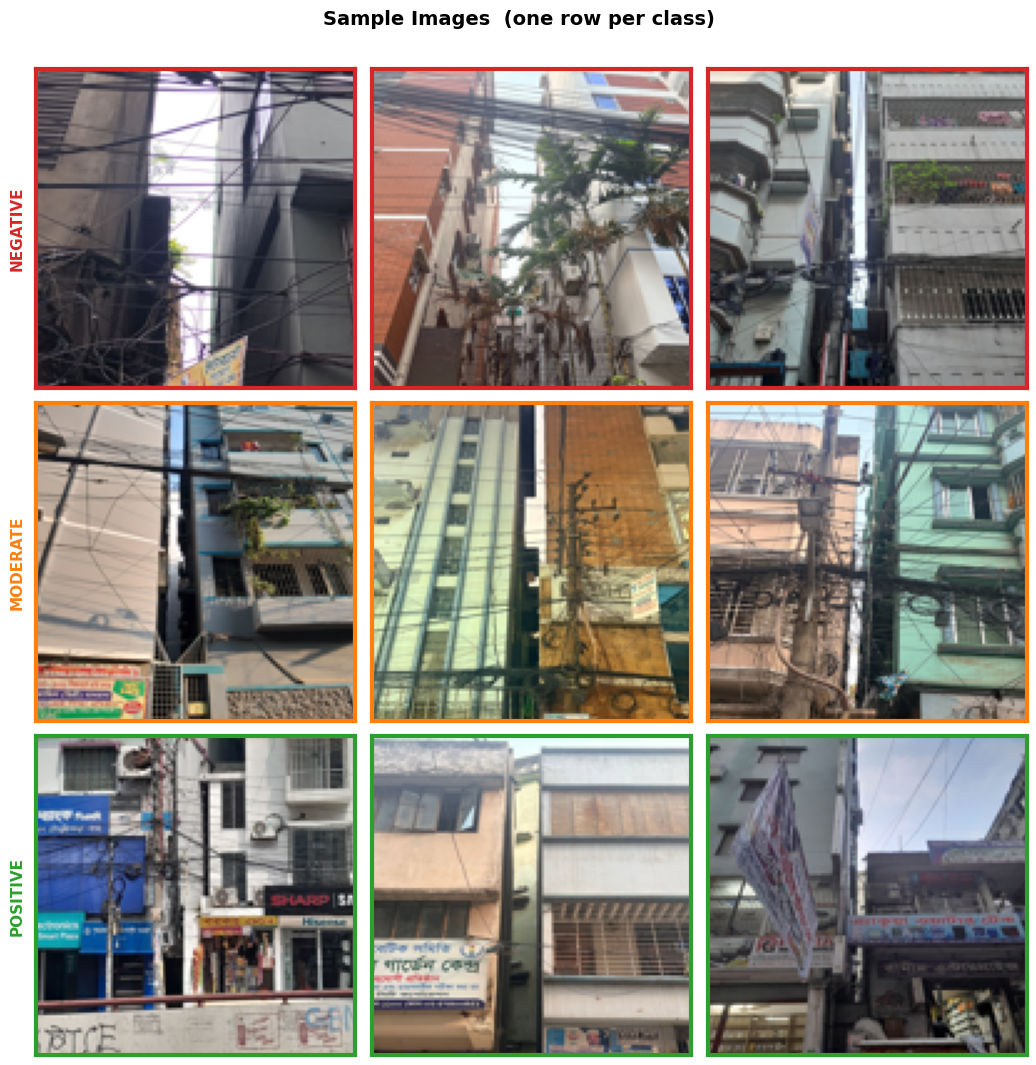

Sample images displayed.


In [12]:
SAMPLES_PER_CLASS = 3
label_to_real_paths = {i: [] for i in range(len(CLASS_NAMES))}
for p, lbl in zip(real_paths, real_labels):
    label_to_real_paths[lbl].append(p)

rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(
    len(CLASS_NAMES), SAMPLES_PER_CLASS,
    figsize=(SAMPLES_PER_CLASS * 3.5, len(CLASS_NAMES) * 3.5)
)
fig.suptitle('Sample Images  (one row per class)', fontsize=14, fontweight='bold', y=1.01)
border_colours = ['#d62728', '#ff7f0e', '#2ca02c']

for cls_idx, cls_name in enumerate(CLASS_NAMES):
    candidates = label_to_real_paths[cls_idx]
    chosen = rng.choice(len(candidates),
                        size=min(SAMPLES_PER_CLASS, len(candidates)),
                        replace=False)
    for col, path_idx in enumerate(chosen):
        ax = axes[cls_idx][col]
        img = Image.open(candidates[path_idx]).convert('RGB').resize(IMAGE_SIZE)
        ax.imshow(np.array(img))
        ax.set_xticks([]); ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_edgecolor(border_colours[cls_idx])
            spine.set_linewidth(3)
        if col == 0:
            ax.set_ylabel(cls_name.upper(), fontsize=11, fontweight='bold',
                          color=border_colours[cls_idx], rotation=90, labelpad=8)

plt.tight_layout()
plt.savefig('sample_images.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sample images displayed.')

## 7. Dataset — Flatten Pixels into MLP Input

An MLP takes a **1D vector** as input. Each image is:
- Resized to 128×128
- Normalised to [0, 1]
- Flattened: 128 × 128 × 3 = **49,152 features**

For the training set, we apply **random flips and slight brightness jitter** before
flattening to add diversity. Val/test are flattened as-is.

RAM estimate: 2,700 images × 49,152 × 4 bytes ≈ **530 MB** — well within 12.7 GB.

In [13]:
import random
from PIL import ImageEnhance, ImageOps


def augment_pil(img: Image.Image) -> Image.Image:
    """Lightweight augmentation for MLP — purely pixel-level, no spatial ops."""
    if random.random() < 0.5:
        img = ImageOps.mirror(img)                          # horizontal flip
    if random.random() < 0.3:
        img = ImageOps.flip(img)                            # vertical flip
    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        img = ImageEnhance.Brightness(img).enhance(factor)  # brightness jitter
    if random.random() < 0.5:
        factor = random.uniform(0.7, 1.3)
        img = ImageEnhance.Contrast(img).enhance(factor)    # contrast jitter
    if random.random() < 0.3:
        factor = random.uniform(0.8, 1.2)
        img = ImageEnhance.Color(img).enhance(factor)       # saturation jitter
    return img


def pil_to_flat_tensor(img: Image.Image) -> torch.Tensor:
    """Convert PIL image → normalised float32 tensor of shape (INPUT_DIM,)."""
    arr = np.asarray(img.resize(IMAGE_SIZE), dtype=np.float32) / 255.0
    return torch.from_numpy(arr.flatten())   # (49152,)


class RajukFlatDataset(Dataset):
    """
    MLP dataset — stores PIL images in RAM (uint8, ~530 MB for 2700 images)
    and converts to flat float32 tensors on the fly in __getitem__.

    If augment=True (training set), random flips/brightness applied per call
    so every epoch sees slightly different pixel values.
    """

    def __init__(self, image_paths, labels, augment: bool = False):
        self.labels  = labels
        self.augment = augment
        n = len(image_paths)
        ram_mb = n * IMAGE_SIZE[0] * IMAGE_SIZE[1] * 3 / 1e6
        print(f'  Caching {n:,} PIL images … (est. {ram_mb:.0f} MB RAM)')
        self.images = []
        for p in image_paths:
            with Image.open(p) as img:
                self.images.append(img.convert('RGB').resize(IMAGE_SIZE, Image.BILINEAR))
        print(f'  Done. augment={augment}')

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.augment:
            img = augment_pil(img)
        return pil_to_flat_tensor(img), self.labels[idx]


if len(train_paths_final) == 0:
    raise ValueError('No labeled images found. Check folder paths and label mapping.')

print('Building datasets:')
train_dataset = RajukFlatDataset(train_paths_final, train_labels_final, augment=True)
val_dataset   = RajukFlatDataset(val_paths_final,   val_labels_final,   augment=False)
test_dataset  = RajukFlatDataset(test_paths_final,  test_labels_final,  augment=False)

total_mb = (len(train_dataset)+len(val_dataset)+len(test_dataset)) * IMAGE_SIZE[0]*IMAGE_SIZE[1]*3 / 1e6
print(f'\nTrain: {len(train_dataset):,}  Val: {len(val_dataset):,}  Test: {len(test_dataset):,}')
print(f'Total image RAM: ~{total_mb:.0f} MB')

# Quick shape check
x0, y0 = train_dataset[0]
print(f'\nSample tensor shape : {x0.shape}  (should be ({INPUT_DIM},))')
print(f'Sample label        : {y0}  ({CLASS_NAMES[y0]})')

Building datasets:
  Caching 4,420 PIL images … (est. 217 MB RAM)
  Done. augment=True
  Caching 57 PIL images … (est. 3 MB RAM)
  Done. augment=False
  Caching 56 PIL images … (est. 3 MB RAM)
  Done. augment=False

Train: 4,420  Val: 57  Test: 56
Total image RAM: ~223 MB

Sample tensor shape : torch.Size([49152])  (should be (49152,))
Sample label        : 1  (moderate)


## 8. DataLoaders

In [14]:
pin = torch.cuda.is_available()
NW  = 2

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=NW, pin_memory=pin)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NW, pin_memory=pin)

print(f'Train : {len(train_dataset):,} samples  ({len(train_loader)} batches)')
print(f'Val   : {len(val_dataset):,} samples  ({len(val_loader)} batches)')
print(f'Test  : {len(test_dataset):,} samples  ({len(test_loader)} batches)')

Train : 4,420 samples  (139 batches)
Val   : 57 samples  (2 batches)
Test  : 56 samples  (2 batches)


## 9. MLP Architecture

A pure **Multi-Layer Perceptron** — only `nn.Linear`, `nn.BatchNorm1d`,
`nn.ReLU`, and `nn.Dropout` layers. Zero convolutions.

```
Input  :  49,152  (128×128×3 flattened pixels)
  └─ Linear(49152 → 2048) + BN + ReLU + Dropout
  └─ Linear(2048  → 1024) + BN + ReLU + Dropout
  └─ Linear(1024  →  512) + BN + ReLU + Dropout
  └─ Linear(512   →  256) + BN + ReLU + Dropout
  └─ Linear(256   →    3) — raw logits
Output :  3 class logits
```

In [15]:
class RajukMLP(nn.Module):
    """
    Bare Multi-Layer Perceptron for image classification.
    Input: flat pixel vector of length input_dim (49,152 for 128x128 RGB).
    No convolutions, no attention, no pretrained weights.
    """

    def __init__(self, input_dim: int, num_classes: int, dropout: float = 0.4):
        super().__init__()

        def block(in_f, out_f):
            return nn.Sequential(
                nn.Linear(in_f, out_f),
                nn.BatchNorm1d(out_f),
                nn.ReLU(inplace=True),
                nn.Dropout(dropout),
            )

        self.net = nn.Sequential(
            block(input_dim, 2048),
            block(2048,      1024),
            block(1024,       512),
            block(512,        256),
            nn.Linear(256, num_classes),   # output logits — no activation
        )

    def forward(self, x):
        return self.net(x)


_tmp = RajukMLP(INPUT_DIM, len(CLASS_NAMES))
total_params = sum(p.numel() for p in _tmp.parameters())
print(f'MLP total parameters: {total_params:,}')
print('Layers:')
for name, mod in _tmp.named_modules():
    if isinstance(mod, nn.Linear):
        print(f'  {name:30s} {mod}')
del _tmp

MLP total parameters: 103,428,099
Layers:
  net.0.0                        Linear(in_features=49152, out_features=2048, bias=True)
  net.1.0                        Linear(in_features=2048, out_features=1024, bias=True)
  net.2.0                        Linear(in_features=1024, out_features=512, bias=True)
  net.3.0                        Linear(in_features=512, out_features=256, bias=True)
  net.4                          Linear(in_features=256, out_features=3, bias=True)


## 10. Weighted Loss & Training Helpers

In [16]:
# ── Weighted loss to handle class imbalance ────────────────────────────────────
train_labels_arr = np.array(train_labels_final, dtype=np.int64)
class_counts     = np.bincount(train_labels_arr, minlength=len(CLASS_NAMES))
class_weights    = torch.tensor(1.0 / (class_counts + 1e-6), dtype=torch.float32).to(device)
class_weights   /= class_weights.sum()

criterion = nn.CrossEntropyLoss(weight=class_weights)

print('Class counts & weights in training set:')
for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights.cpu()):
    print(f'  {name:10s}: {cnt:,} samples  →  weight {w:.4f}')


# ── Train / evaluate ──────────────────────────────────────────────────────────
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss = correct = total = 0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(X)
        loss   = criterion(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * X.size(0)
        correct    += (logits.argmax(1) == y).sum().item()
        total      += X.size(0)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = correct = total = 0
    all_preds, all_true = [], []
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)
        loss   = criterion(logits, y)
        total_loss += loss.item() * X.size(0)
        preds = logits.argmax(1)
        correct += (preds == y).sum().item()
        total   += X.size(0)
        all_preds.extend(preds.cpu().numpy())
        all_true.extend(y.cpu().numpy())
    return total_loss / total, correct / total, all_preds, all_true


def make_model():
    m   = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
    opt = optim.AdamW(m.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sch = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=NUM_EPOCHS, eta_min=1e-6)
    return m, opt, sch


print('\nHelpers defined.')

Class counts & weights in training set:
  negative  : 2,720 samples  →  weight 0.1328
  moderate  : 969 samples  →  weight 0.3729
  positive  : 731 samples  →  weight 0.4943

Helpers defined.


## 11. K-Fold Cross-Validation on Real Training Images Only

K-Fold runs on **real training images only** (not augmented copies) so
fold accuracy numbers are honest — no near-duplicate images leaking
across fold boundaries.

In [17]:
# Build a real-only training dataset for K-Fold
real_train_paths  = [p for p in train_paths_final
                     if str(AUGMENTED_DIR).lower() not in str(p).lower()]
real_train_labels = [l for p, l in zip(train_paths_final, train_labels_final)
                     if str(AUGMENTED_DIR).lower() not in str(p).lower()]

print(f'Real training images for K-Fold: {len(real_train_paths):,}')

kfold_dataset   = RajukFlatDataset(real_train_paths, real_train_labels, augment=True)
kfold_labels    = np.array(real_train_labels, dtype=np.int64)
kfold_indices   = np.arange(len(kfold_dataset))

min_cls = np.min(np.bincount(kfold_labels, minlength=len(CLASS_NAMES)))
k       = min(KFOLD_SPLITS, int(min_cls))
kfold   = StratifiedKFold(n_splits=k, shuffle=True, random_state=SEED)

fold_val_accs     = []
best_global_acc   = -1.0
best_global_state = None

for fold, (tr, va) in enumerate(kfold.split(kfold_indices, kfold_labels)):
    print(f'\n{"─"*58}')
    print(f'  Fold {fold+1}/{k}   |   train={len(tr):,}   val={len(va):,}')
    print(f'{"─"*58}')

    fold_train_loader = DataLoader(
        Subset(kfold_dataset, tr),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )
    fold_val_loader = DataLoader(
        Subset(kfold_dataset, va),
        batch_size=BATCH_SIZE, shuffle=False, num_workers=NW, pin_memory=pin
    )

    model, optimizer, scheduler = make_model()
    best_fold_acc   = -1.0
    best_fold_state = None
    patience_ctr    = 0

    for epoch in range(NUM_EPOCHS):
        tr_loss, tr_acc = train_one_epoch(model, fold_train_loader, optimizer)
        vl_loss, vl_acc, _, _ = evaluate(model, fold_val_loader)
        scheduler.step()

        print(f'  Ep {epoch+1:02d}/{NUM_EPOCHS}  '
              f'Train Loss={tr_loss:.4f} Acc={tr_acc:.4f}  |  '
              f'Val   Loss={vl_loss:.4f} Acc={vl_acc:.4f}')

        if vl_acc > best_fold_acc:
            best_fold_acc   = vl_acc
            patience_ctr    = 0
            best_fold_state = {k2: v.cpu() for k2, v in model.state_dict().items()}
        else:
            patience_ctr += 1
            if patience_ctr >= PATIENCE:
                print(f'  Early stopping at epoch {epoch+1}.')
                break

    fold_val_accs.append(best_fold_acc)
    print(f'  → Fold {fold+1} best val acc: {best_fold_acc:.4f}')

    if best_fold_acc > best_global_acc:
        best_global_acc   = best_fold_acc
        best_global_state = best_fold_state

print(f'\nCross-val accuracies : {[f"{a:.4f}" for a in fold_val_accs]}')
print(f'Mean CV accuracy     : {np.mean(fold_val_accs):.4f} ± {np.std(fold_val_accs):.4f}')

Real training images for K-Fold: 260
  Caching 260 PIL images … (est. 13 MB RAM)
  Done. augment=True

──────────────────────────────────────────────────────────
  Fold 1/5   |   train=208   val=52
──────────────────────────────────────────────────────────
  Ep 01/60  Train Loss=1.1658 Acc=0.3029  |  Val   Loss=1.8448 Acc=0.6154
  Ep 02/60  Train Loss=1.2115 Acc=0.4038  |  Val   Loss=1.3749 Acc=0.3077
  Ep 03/60  Train Loss=1.1152 Acc=0.4183  |  Val   Loss=1.3757 Acc=0.2115
  Ep 04/60  Train Loss=1.1368 Acc=0.4327  |  Val   Loss=1.3947 Acc=0.3462
  Ep 05/60  Train Loss=1.0994 Acc=0.5000  |  Val   Loss=1.2118 Acc=0.3269
  Ep 06/60  Train Loss=1.0749 Acc=0.4760  |  Val   Loss=1.1175 Acc=0.5577
  Ep 07/60  Train Loss=1.1933 Acc=0.3894  |  Val   Loss=1.1955 Acc=0.3654
  Ep 08/60  Train Loss=1.1113 Acc=0.4615  |  Val   Loss=1.0870 Acc=0.4231
  Ep 09/60  Train Loss=1.0892 Acc=0.3846  |  Val   Loss=1.1436 Acc=0.3654
  Ep 10/60  Train Loss=1.0698 Acc=0.4375  |  Val   Loss=1.1401 Acc=0.4615
  E

## 12. Fine-tune Best Model on Full Train Set → Evaluate on Val + Test

In [18]:
final_model = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
final_model.load_state_dict({k: v.to(device) for k, v in best_global_state.items()})

ft_optimizer = optim.AdamW(final_model.parameters(), lr=LR / 5, weight_decay=WEIGHT_DECAY)

print('Fine-tuning on full training split …')
for epoch in range(5):
    t_loss, t_acc = train_one_epoch(final_model, train_loader, ft_optimizer)
    print(f'  FT Epoch {epoch+1}/5  Loss={t_loss:.4f}  Acc={t_acc:.4f}')

val_loss,  val_acc,  val_preds,  val_true  = evaluate(final_model, val_loader)
test_loss, test_acc, test_preds, test_true = evaluate(final_model, test_loader)

print(f'\n{"="*50}')
print(f'  Validation — Loss: {val_loss:.4f}   Acc: {val_acc:.4f}')
print(f'  Test       — Loss: {test_loss:.4f}   Acc: {test_acc:.4f}')
print(f'{"="*50}')

Fine-tuning on full training split …
  FT Epoch 1/5  Loss=1.0358  Acc=0.4518
  FT Epoch 2/5  Loss=0.7089  Acc=0.6477
  FT Epoch 3/5  Loss=0.4298  Acc=0.7968
  FT Epoch 4/5  Loss=0.3182  Acc=0.8647
  FT Epoch 5/5  Loss=0.2549  Acc=0.8928

  Validation — Loss: 2.0980   Acc: 0.4211
  Test       — Loss: 1.8519   Acc: 0.5000


## 13. Classification Report & Confusion Matrix

Test Set — Classification Report
──────────────────────────────────────────────────
              precision    recall  f1-score   support

    negative       0.76      0.54      0.63        35
    moderate       0.29      0.58      0.39        12
    positive       0.29      0.22      0.25         9

    accuracy                           0.50        56
   macro avg       0.45      0.45      0.42        56
weighted avg       0.58      0.50      0.52        56



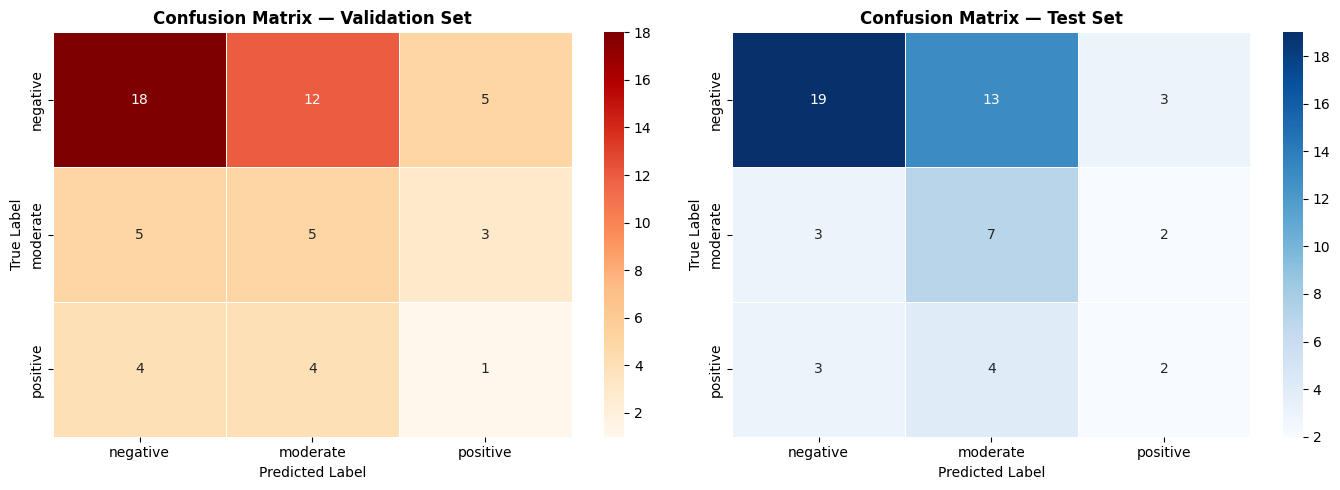

In [19]:
print('Test Set — Classification Report')
print('─' * 50)
print(classification_report(test_true, test_preds, target_names=CLASS_NAMES))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (preds, true, title, cmap) in zip(
    axes,
    [
        (val_preds,  val_true,  'Confusion Matrix — Validation Set', 'OrRd'),
        (test_preds, test_true, 'Confusion Matrix — Test Set',       'Blues'),
    ]
):
    cm = confusion_matrix(true, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                linewidths=0.5, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=120, bbox_inches='tight')
plt.show()

## 14. Learning Curves — Error vs. Dataset Size

| Marker | Meaning |
|--------|---------|
| 🔵 Blue circle | **Training error** |
| 🟠 Orange triangle | **Validation error** |
| 🟢 Green square | **Test error** |

In [20]:
def train_and_measure(n_train: int):
    actual_n = min(n_train, len(train_dataset))
    if actual_n < len(CLASS_NAMES):
        return None

    sub_idx, _ = train_test_split(
        np.arange(len(train_dataset)),
        train_size=actual_n,
        random_state=SEED,
        stratify=train_labels_arr
    )
    sub_loader = DataLoader(
        Subset(train_dataset, sub_idx),
        batch_size=BATCH_SIZE, shuffle=True, num_workers=NW, pin_memory=pin
    )

    m, opt, sch = make_model()
    for _ in range(min(15, NUM_EPOCHS)):
        train_one_epoch(m, sub_loader, opt)
        sch.step()

    tr_loss, _, _, _ = evaluate(m, sub_loader)
    vl_loss, _, _, _ = evaluate(m, val_loader)
    te_loss, _, _, _ = evaluate(m, test_loader)
    return tr_loss, vl_loss, te_loss


curve_sizes, curve_train, curve_val, curve_test = [], [], [], []

for n in DATASET_STEPS:
    if n > len(train_dataset):
        print(f'  n={n}: exceeds train size ({len(train_dataset)}), skipping.')
        break
    print(f'  Training on n={n} …', end=' ', flush=True)
    result = train_and_measure(n)
    if result is None:
        print('skipped.'); continue
    tr_l, vl_l, te_l = result
    curve_sizes.append(n)
    curve_train.append(tr_l)
    curve_val.append(vl_l)
    curve_test.append(te_l)
    print(f'train={tr_l:.4f}  val={vl_l:.4f}  test={te_l:.4f}')

print('\nLearning-curve data collected.')

  Training on n=100 … train=0.9883  val=1.0843  test=1.0878
  Training on n=200 … train=0.8039  val=1.0779  test=1.1268
  Training on n=300 … train=0.7837  val=1.4088  test=1.0774
  Training on n=400 … train=0.7104  val=1.4429  test=1.0521
  Training on n=500 … train=0.7293  val=1.3264  test=1.3260
  Training on n=600 … train=0.4221  val=1.6236  test=1.8648
  Training on n=700 … train=0.6660  val=1.7981  test=1.5824
  Training on n=800 … train=0.6026  val=1.7450  test=1.6990
  Training on n=900 … train=0.5780  val=1.9489  test=1.5297
  Training on n=1000 … train=0.3269  val=1.9418  test=1.5772

Learning-curve data collected.


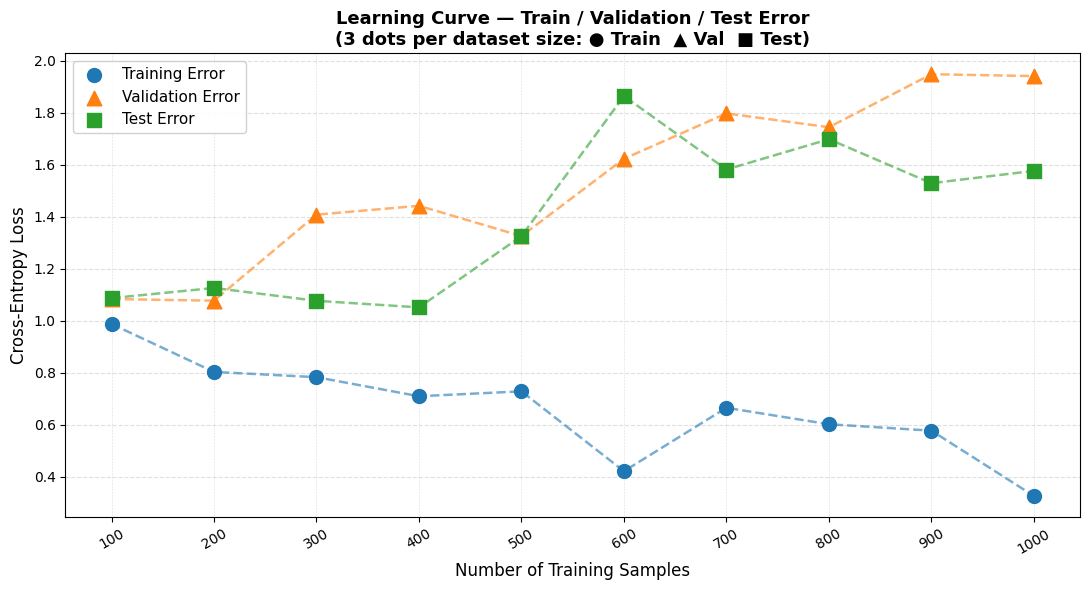

In [21]:
fig, ax = plt.subplots(figsize=(11, 6))

ax.plot(curve_sizes, curve_train, color='#1f77b4', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_val,   color='#ff7f0e', linewidth=1.8, linestyle='--', alpha=0.6)
ax.plot(curve_sizes, curve_test,  color='#2ca02c', linewidth=1.8, linestyle='--', alpha=0.6)

ax.scatter(curve_sizes, curve_train, marker='o', s=100,
           color='#1f77b4', zorder=5, label='Training Error')
ax.scatter(curve_sizes, curve_val,   marker='^', s=110,
           color='#ff7f0e', zorder=5, label='Validation Error')
ax.scatter(curve_sizes, curve_test,  marker='s', s=100,
           color='#2ca02c', zorder=5, label='Test Error')

for s in curve_sizes:
    ax.axvline(s, color='grey', linewidth=0.4, linestyle=':', alpha=0.5)

ax.set_xlabel('Number of Training Samples', fontsize=12)
ax.set_ylabel('Cross-Entropy Loss', fontsize=12)
ax.set_title('Learning Curve — Train / Validation / Test Error\n'
             '(3 dots per dataset size: ● Train  ▲ Val  ■ Test)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11, framealpha=0.9)
ax.set_xticks(curve_sizes)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('learning_curve.png', dpi=130, bbox_inches='tight')
plt.show()

## 15. Full Training History (MLP on Full Train Set)

In [22]:
history_model, history_opt, history_sch = make_model()
h = {'train_loss': [], 'val_loss': [], 'test_loss': [],
     'train_acc':  [], 'val_acc':  [], 'test_acc':  []}

best_acc_ht   = -1.0
best_state_ht = None
patience_ht   = 0

print(f'Training MLP for up to {NUM_EPOCHS} epochs …\n')
for epoch in range(NUM_EPOCHS):
    tr_l, tr_a = train_one_epoch(history_model, train_loader, history_opt)
    vl_l, vl_a, _, _ = evaluate(history_model, val_loader)
    te_l, te_a, _, _ = evaluate(history_model, test_loader)
    history_sch.step()

    for key, val in zip(
        ['train_loss','val_loss','test_loss','train_acc','val_acc','test_acc'],
        [tr_l, vl_l, te_l, tr_a, vl_a, te_a]
    ):
        h[key].append(val)

    print(f'Ep {epoch+1:02d}/{NUM_EPOCHS}  '
          f'Train L={tr_l:.4f} A={tr_a:.4f} | '
          f'Val L={vl_l:.4f} A={vl_a:.4f} | '
          f'Test L={te_l:.4f} A={te_a:.4f}')

    if vl_a > best_acc_ht:
        best_acc_ht   = vl_a
        patience_ht   = 0
        best_state_ht = {k2: v.cpu() for k2, v in history_model.state_dict().items()}
    else:
        patience_ht += 1
        if patience_ht >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}.')
            break

print(f'\nBest validation accuracy: {best_acc_ht:.4f}')

Training MLP for up to 60 epochs …

Ep 01/60  Train L=1.1190 A=0.4256 | Val L=1.0077 A=0.4737 | Test L=1.0867 A=0.4107
Ep 02/60  Train L=0.9708 A=0.5190 | Val L=1.4320 A=0.5439 | Test L=1.3678 A=0.5714
Ep 03/60  Train L=0.6492 A=0.6776 | Val L=2.0222 A=0.5088 | Test L=1.7898 A=0.5357
Ep 04/60  Train L=0.4962 A=0.7731 | Val L=2.1917 A=0.5439 | Test L=1.9488 A=0.5714
Ep 05/60  Train L=0.3784 A=0.8342 | Val L=2.0379 A=0.4561 | Test L=2.1114 A=0.4643
Ep 06/60  Train L=0.2894 A=0.8778 | Val L=2.6596 A=0.4386 | Test L=2.6800 A=0.4107
Ep 07/60  Train L=0.2839 A=0.8842 | Val L=1.9867 A=0.4561 | Test L=1.7779 A=0.4286
Ep 08/60  Train L=0.2042 A=0.9145 | Val L=2.3074 A=0.5614 | Test L=2.8581 A=0.4821
Ep 09/60  Train L=0.1881 A=0.9233 | Val L=2.8654 A=0.4737 | Test L=2.9064 A=0.3750
Ep 10/60  Train L=0.1884 A=0.9233 | Val L=2.4308 A=0.4912 | Test L=2.1793 A=0.5179
Ep 11/60  Train L=0.1465 A=0.9441 | Val L=2.5674 A=0.4035 | Test L=2.1315 A=0.5000
Ep 12/60  Train L=0.1373 A=0.9468 | Val L=3.3566 A=

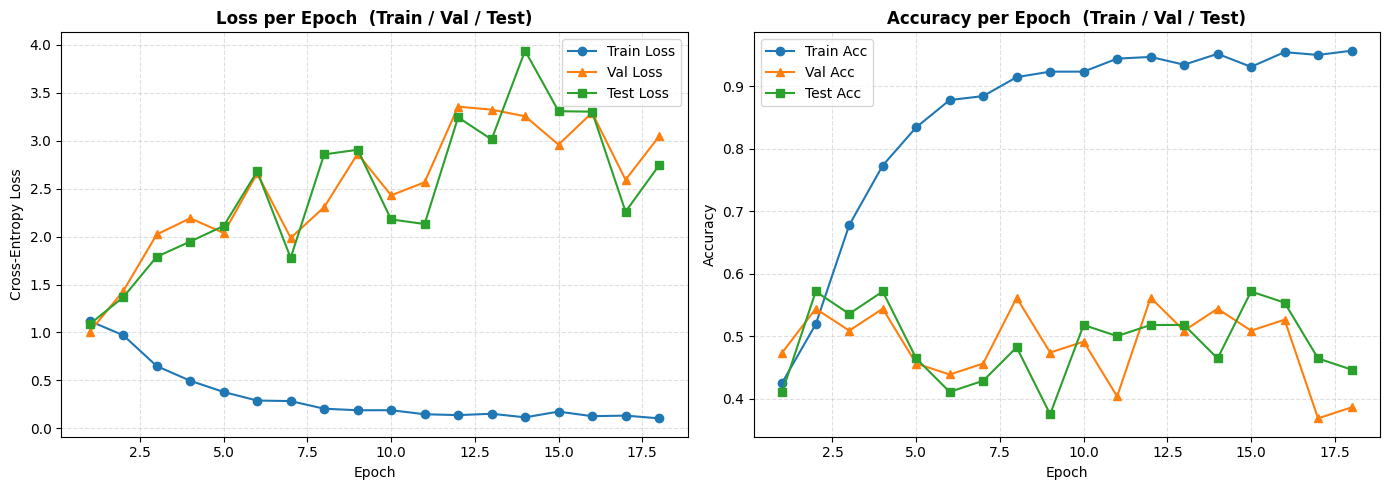

In [23]:
epochs_ran = range(1, len(h['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_ran, h['train_loss'], 'o-', color='#1f77b4', label='Train Loss')
ax1.plot(epochs_ran, h['val_loss'],   '^-', color='#ff7f0e', label='Val Loss')
ax1.plot(epochs_ran, h['test_loss'],  's-', color='#2ca02c', label='Test Loss')
ax1.set_title('Loss per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch'); ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend(); ax1.grid(linestyle='--', alpha=0.4)

ax2.plot(epochs_ran, h['train_acc'], 'o-', color='#1f77b4', label='Train Acc')
ax2.plot(epochs_ran, h['val_acc'],   '^-', color='#ff7f0e', label='Val Acc')
ax2.plot(epochs_ran, h['test_acc'],  's-', color='#2ca02c', label='Test Acc')
ax2.set_title('Accuracy per Epoch  (Train / Val / Test)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Accuracy')
ax2.legend(); ax2.grid(linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('training_history.png', dpi=130, bbox_inches='tight')
plt.show()

## 16. Save Model

In [24]:
save_path = DRIVE_BASE / 'rajuk_mlp.pth'

artifact = {
    'model_state_dict' : best_state_ht,
    'class_names'      : CLASS_NAMES,
    'image_size'       : IMAGE_SIZE,
    'input_dim'        : INPUT_DIM,
    'label_source'     : str(source_path),
    'label_column'     : level_col,
    'best_val_acc'     : best_acc_ht,
    'kfold_val_accs'   : fold_val_accs,
    'train_size'       : len(train_dataset),
    'val_size'         : len(val_dataset),
    'test_size'        : len(test_dataset),
    'final_test_acc'   : test_acc,
}

torch.save(artifact, save_path)
print(f'Model saved to  : {save_path}')
print(f'Final test acc  : {test_acc:.4f}')

Model saved to  : /content/drive/MyDrive/ML_Lab/rajuk_mlp.pth
Final test acc  : 0.5000


## 17. Sanity Check — Predict on Random Test Samples

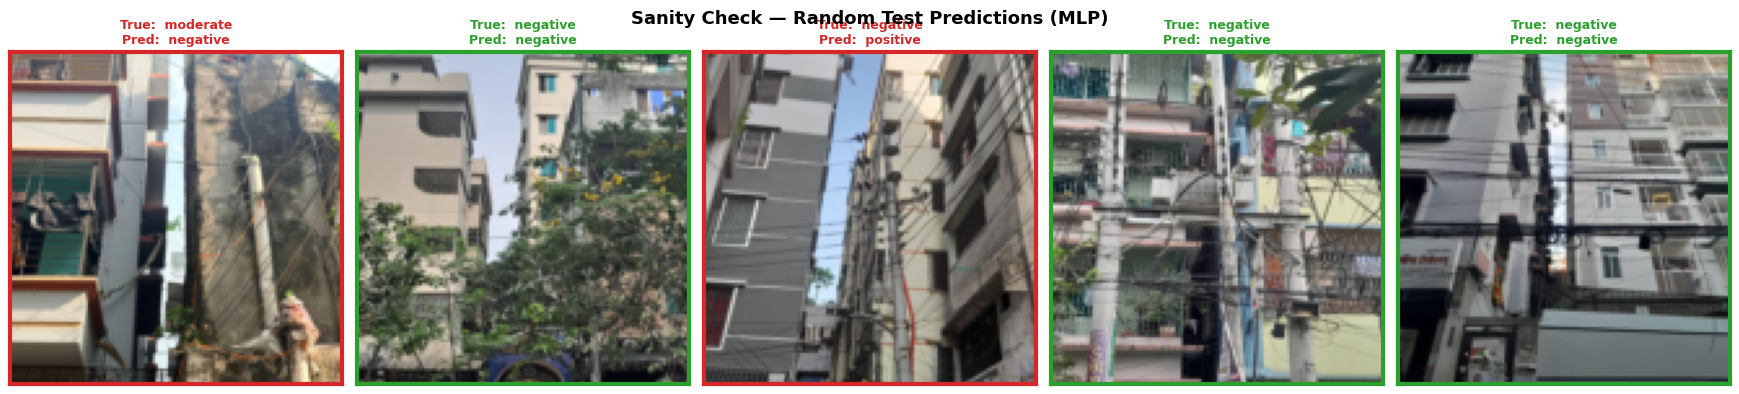

Sanity check complete.


In [25]:
best_model = RajukMLP(INPUT_DIM, len(CLASS_NAMES), dropout=DROPOUT).to(device)
best_model.load_state_dict({k: v.to(device) for k, v in best_state_ht.items()})
best_model.eval()

rng2   = np.random.default_rng(SEED + 1)
sample = rng2.choice(len(test_dataset), size=min(5, len(test_dataset)), replace=False)

fig, axes = plt.subplots(1, len(sample), figsize=(len(sample) * 3.5, 4))
fig.suptitle('Sanity Check — Random Test Predictions (MLP)', fontsize=13, fontweight='bold')

with torch.no_grad():
    for ax, s_idx in zip(axes, sample):
        flat_tensor, true_lbl = test_dataset[int(s_idx)]
        logits   = best_model(flat_tensor.unsqueeze(0).to(device))
        pred_lbl = logits.argmax(1).item()

        # Reshape flat tensor back to image for display
        img_np = flat_tensor.numpy().reshape(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
        img_np = np.clip(img_np, 0, 1)

        ax.imshow(img_np)
        ax.set_xticks([]); ax.set_yticks([])

        colour = '#2ca02c' if pred_lbl == true_lbl else '#d62728'
        ax.set_title(
            f'True:  {CLASS_NAMES[true_lbl]}\nPred:  {CLASS_NAMES[pred_lbl]}',
            fontsize=9, color=colour, fontweight='bold'
        )
        for spine in ax.spines.values():
            spine.set_edgecolor(colour); spine.set_linewidth(3)

plt.tight_layout()
plt.savefig('sanity_predictions.png', dpi=120, bbox_inches='tight')
plt.show()
print('Sanity check complete.')